# Assignment 4 – Response to weather: single-storey two-zone office building (Chur)

**Team:** _Valerio Paganini_

One year of Chur weather on the building of Assignment 1 ([Assignment1_Model.ipynb](Assignment1_Model.ipynb)),
with $A$, $G$, $C$ and the state space of Assignment 2 ([Assignment2_SteadyState.ipynb](Assignment2_SteadyState.ipynb))
and the time step from Assignment 3 ([Assignment3_StepResponse.ipynb](Assignment3_StepResponse.ipynb)).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import linprog
import dm4bem
from IPython.utils import io

with io.capture_output():                   # model (Assignment 1) and state space (Assignment 2), outputs not shown
    %run Assignment2_SteadyState.ipynb

states = np.flatnonzero(np.diag(C))         # nodes with capacity = state variables
bT, fQ = np.flatnonzero(b_ptr), np.flatnonzero(f_ptr)
jb = {k: j for j, k in enumerate(bT)}                   # branch with temperature source -> column of u
jf = {i: len(bT) + j for j, i in enumerate(fQ)}         # node with flow-rate source -> column of u
print(f'{len(states)} state variables, {len(bT)} + {len(fQ)} = {len(u_names)} inputs, outputs θ{air1}, θ{air2}')

72 state variables, 20 + 28 = 48 inputs, outputs θ71, θ144


## 1 Start and end time

Typical weather year of Chur (TMYx 2004–2018, hypothesis 4) on the time axis of 2023 (starts on a Sunday). The
concrete has time constants of up to 18 days (Assignment 3), so a 30-day warm-up with the last 30 days of the
year runs first (assumption) and is excluded from the results.

Time step 15 min, implicit Euler; explicit Euler would need $\Delta t$ < 16 s with the P-controller
(Assignment 3). The step size is checked in section 5.

In [2]:
year, dt = 2023, 900                        # time axis; s, time step (implicit Euler)
start, end = f'{year}-01-01 00:00', f'{year}-12-31 23:45'
warmup = 30                                  # d, warm-up before the start (assumption)
print(f'{start} to {end}, Δt = {dt / 60:.0f} min, warm-up {warmup} d')

2023-01-01 00:00 to 2023-12-31 23:45, Δt = 15 min, warm-up 30 d


## 2 Inputs

### Weather data and solar irradiance on the walls

Irradiance per surface from `dm4bem.read_epw` and `dm4bem.sol_rad_tilt_surf` (azimuth 0 = south, west positive;
albedo 0.2, assumption), with two corrections. First, `read_epw` labels hourly values with the start of the hour
but `sol_rad_tilt_surf` puts the sun at the end (`minute + 60`, clock time). The middle of the hour in solar time
is $0.5\,\text{h} + (15° \cdot 1 - 9.53°)/15°\,\text{h} = 0.86$ h (52 min) earlier for Chur (UTC+1, 9.53° E;
equation of time neglected), so the time is shifted by that; otherwise east would get 37 % less and west 35 % more
direct radiation. Second, the ground-reflected part uses $1 - \cos\beta / 2$ instead of the view factor
$(1 - \cos\beta)/2$ (Duffie & Beckman), which doubles it on the façades, so it is corrected.

In [3]:
weather, meta = dm4bem.read_epw('daten/CHE_GR_Chur.067860_TMYx.2004-2018.epw', coerce_year=year)
p_v = 611.2 * np.exp(17.62 * weather['temp_dew'] / (243.12 + weather['temp_dew']))   # Pa, vapour pressure (Magnus)
w_o = 0.622 * p_v / (weather['atmospheric_pressure'] - p_v)                             # kg/kg, humidity ratio
weather = weather[['temp_air', 'dir_n_rad', 'dif_h_rad']]
albedo = 0.2
surfaces = {'S': (90, 0), 'E': (90, -90), 'W': (90, 90), 'N': (90, 180), 'roof': (0, 0)}   # slope, azimuth
shift = pd.Timedelta(hours=0.5 + (15 * meta['TZ'] - meta['longitude']) / 15)   # see the first point above
w_sun = weather.copy()
w_sun.index = w_sun.index - shift
E = {}
for o, (slope, azimuth) in surfaces.items():
    rad = dm4bem.sol_rad_tilt_surf(w_sun, {'slope': slope, 'azimuth': azimuth, 'latitude': meta['latitude']},
                                   albedo)
    rad.index = weather.index
    cb = np.cos(np.radians(slope))
    rad['reflected'] *= ((1 - cb) / 2) / (1 - cb / 2)         # view factor to the ground (see above)
    E[o] = rad.sum(axis=1)
weather = pd.DataFrame({'T_o': weather['temp_air'], **{f'E_{o}': e for o, e in E.items()}, 'w_o': w_o})
weather.index = weather.index.tz_localize(None)
print(f'latitude {meta["latitude"]}°, T_o mean {weather["T_o"].mean():.1f} °C, '
      f'min {weather["T_o"].min():.1f} °C, max {weather["T_o"].max():.1f} °C')
print(f'humidity ratio outdoors: mean {1e3 * w_o.mean():.1f} g/kg, max {1e3 * w_o.max():.1f} g/kg')
(weather.filter(like='E_').sum() / 1000).round(0).rename('solar irradiation, kWh/(m²·a)').to_frame().T

latitude 46.8703°, T_o mean 10.4 °C, min -11.2 °C, max 31.7 °C
humidity ratio outdoors: mean 6.3 g/kg, max 14.9 g/kg


,E_S,E_E,E_W,E_N,E_roof
"solar irradiation, kWh/(m²·a)",1138.0,732.0,829.0,468.0,1449.0


### Resampling and warm-up

Linear interpolation to the time step; the last 30 days are put in front as warm-up.

In [4]:
pre = weather.loc[weather.index[-1] - pd.Timedelta(days=warmup):].iloc[1:].copy()
pre.index = pre.index - pd.Timedelta(days=365)                 # last 30 days, one year earlier
w = pd.concat([pre, weather]).resample(f'{dt}s').interpolate()
w = w.loc[:end]
t = w.index
n = len(t)
k0 = t.get_loc(pd.Timestamp(start))                            # first time step of the year
print(f'{n} time steps ({k0} of warm-up), {t[0]} to {t[-1]}')

37917 time steps (2880 of warm-up), 2022-12-02 00:00:00 to 2023-12-31 23:00:00


### Other inputs

Internal gains (hypothesis 9; SIA 2024 room type 3.01, assumption), all convective on the air node: occupancy
Mon–Fri 07:00–18:00; occupants 84 W per person at 14 m² per person and equipment 11 W/m², with hourly profiles and
an annual factor of 0.8 (holidays, absence); equipment at least 30 % (stand-by), weekends included; lighting
9.72 W/m² during occupancy, scaled to 13.45 kWh/m² per year.

Set-points (hypothesis 12): heating/cooling 21/26 °C during occupancy, 18/28 °C otherwise.
Basement (hypothesis 5): $T_{bsmt} = 20 - 0.7\,(20 - T_{o,24h})$, $T_{o,24h}$ = 24-hour mean of $T_o$.

Solar radiation (hypothesis 8; values assumed):

| Quantity | Value |
|---|---|
| absorptivity façade / roof | 0.5 / 0.6 |
| glazing: transmitted / absorbed | 0.40 / 0.20 (g ≈ 0.5 incl. absorbed part going inside) |
| horizon, reveals, angle of incidence $F_{sol}$ | 0.65 |
| frame (no solar gain) | 20 % of the window |
| external blinds closed: factor on transmitted and absorbed | 0.20 ($g_{tot} \approx 0.10$) |
| blinds closed if | façade irradiance > 200 W/m² and 24-hour mean $T_o$ > 12 °C |
| transmitted radiation | 50 % on the floor, 50 % on walls, roof and interior wall by area (not windows) |

The blind rule depends only on the weather, so all inputs are known in advance (also for the MPC).

In [5]:
p_persons = np.array([0, 0, 0, 0, 0, 0, 0, 0.2, 0.6, 1, 1, 0.8, 0.4, 0.6, 1, 0.8, 0.6, 0.2, 0, 0, 0, 0, 0, 0])
p_equip = np.array([0.3] * 8 + [0.6, 0.8, 1, 0.8, 0.4, 0.6, 1, 0.8, 0.6] + [0.3] * 7)
f_year, f_standby = 0.8, 0.3                                     # annual factor, stand-by share of equipment

workday = t.dayofweek < 5
h = t.hour + t.minute / 60
occupied = workday & (h >= 7) & (h < 18)
q_pers = np.where(workday, p_persons[t.hour] * f_year, 0) * 84 / 14          # W/m²
q_equip = np.where(workday, np.maximum(p_equip[t.hour] * f_year, f_standby), f_standby) * 11
f_light = 13.45e3 / (9.72 * occupied[k0:].sum() * dt / 3600)                  # annual energy 13.45 kWh/m²
q_light = np.where(occupied, f_light, 0) * 9.72
q_int = q_pers + q_equip + q_light                                            # W/m² of floor

T_h = np.where(occupied, 21.0, 18.0)                             # °C, heating set-point
T_c = np.where(occupied, 26.0, 28.0)                             # °C, cooling set-point
T_o24 = w['T_o'].rolling('24h', min_periods=1).mean().to_numpy()
T_bsmt = 20 - 0.7 * (20 - T_o24)

alpha_wall, alpha_roof = 0.5, 0.6
tau_g, alpha_g, F_sol, F_c = 0.40, 0.20, 0.65, 0.20
blind = {o: (w[f'E_{o}'].to_numpy() > 200) & (T_o24 > 12) for o in ('S', 'E', 'W', 'N')}
print(f'internal gains: mean {q_int[k0:].mean():.1f} W/m², max {q_int.max():.1f} W/m², '
      f'{q_int[k0:].sum() * dt / 3.6e6:.1f} kWh/(m²·a); lighting factor {f_light:.2f}')
print('blinds closed (h/a): ' + ', '.join(f'{o} {blind[o][k0:].sum() * dt / 3600:.0f}' for o in blind))

internal gains: mean 6.7 W/m², max 18.3 W/m², 58.7 kWh/(m²·a); lighting factor 0.48
blinds closed (h/a): S 1208, E 863, W 984, N 270


### Input vector in time

One row per time step, 48 columns as in Assignment 2: temperature sources $b_T$ (branches), then flow-rate
sources $f_Q$ (nodes). Nodes of zone 1 (zone 2: + 73): outer surfaces
$\theta_0, \theta_{15}, \theta_{30}$ (walls S, E, W), $\theta_{45}$ (roof); glass $\theta_{13}, \theta_{28},
\theta_{43}$; inner surfaces $\theta_{12}, \theta_{27}, \theta_{42}$ (walls), $\theta_{57}$ (roof),
$\theta_{70}$ (floor); interior wall $\theta_{146}$ (zone 1 side), $\theta_{154}$ (zone 2 side); air
$\theta_{71}$. The controller sets $T_{sp}$ in the time loop.

In [6]:
U = np.zeros((n, len(u_names)))
for k in bT:                                                     # temperature sources
    U[:, jb[k]] = {'T_o': w['T_o'].to_numpy(), 'T_bsmt': T_bsmt}.get(src[k], 0.0)
j_sp = [jb[k] for k in k_ctrl]                                   # columns of T_sp,1 and T_sp,2

Q_sol = {}                                                       # W, transmitted solar radiation per zone
for z, n0, o1, iw in ((1, 0, 'S', 146), (2, 73, 'N', 154)):
    Q_t = np.zeros(n)
    for o, size, k_out, k_g in ((o1, 'long', 0, 13), ('E', 'short', 15, 28), ('W', 'short', 30, 43)):
        E_o = w[f'E_{o}'].to_numpy()
        S_g = S_win[size] * (1 - frame)                          # glass area
        shade = np.where(blind[o], F_c, 1.0)
        U[:, jf[n0 + k_out]] += alpha_wall * S_wall[size] * E_o                 # Φo, outer wall surface
        U[:, jf[n0 + k_g]] += alpha_g * F_sol * shade * S_g * E_o               # Φa, glass
        Q_t += tau_g * F_sol * shade * S_g * E_o
    U[:, jf[n0 + 45]] += alpha_roof * S_plan * w['E_roof'].to_numpy()           # Φo, roof
    inner = {n0 + 12: S_wall['long'], n0 + 27: S_wall['short'], n0 + 42: S_wall['short'],
             n0 + 57: S_plan, iw: S_iw}                                         # inner surfaces except the floor
    U[:, jf[n0 + 70]] += 0.5 * Q_t                                              # Φi, floor
    for node, S in inner.items():
        U[:, jf[node]] += 0.5 * Q_t * S / sum(inner.values())                   # Φi, other inner surfaces
    U[:, jf[n0 + 71]] += S_plan * q_int                                         # internal gains, air
    Q_sol[z] = Q_t
U = pd.DataFrame(U, index=t, columns=u_names)
U.loc[f'{year}-07-17':f'{year}-07-17 23:45'].iloc[::8].loc[:, lambda d: d.abs().sum() > 0].round(0).T

,2023-07-17 00:00:00,2023-07-17 02:00:00,2023-07-17 04:00:00,2023-07-17 06:00:00,2023-07-17 08:00:00,2023-07-17 10:00:00,2023-07-17 12:00:00,2023-07-17 14:00:00,2023-07-17 16:00:00,2023-07-17 18:00:00,2023-07-17 20:00:00,2023-07-17 22:00:00
b: q0 (T_o),13.0,11.0,9.0,9.0,11.0,16.0,19.0,20.0,21.0,20.0,17.0,14.0
b: q15 (T_o),13.0,11.0,9.0,9.0,11.0,16.0,19.0,20.0,21.0,20.0,17.0,14.0
b: q19 (T_o),13.0,11.0,9.0,9.0,11.0,16.0,19.0,20.0,21.0,20.0,17.0,14.0
b: q34 (T_o),13.0,11.0,9.0,9.0,11.0,16.0,19.0,20.0,21.0,20.0,17.0,14.0
b: q38 (T_o),13.0,11.0,9.0,9.0,11.0,16.0,19.0,20.0,21.0,20.0,17.0,14.0
b: q53 (T_o),13.0,11.0,9.0,9.0,11.0,16.0,19.0,20.0,21.0,20.0,17.0,14.0
b: q57 (T_o),13.0,11.0,9.0,9.0,11.0,16.0,19.0,20.0,21.0,20.0,17.0,14.0
b: q72 (T_bsmt),15.0,15.0,15.0,15.0,15.0,15.0,15.0,15.0,16.0,16.0,16.0,17.0
b: q87 (T_o),13.0,11.0,9.0,9.0,11.0,16.0,19.0,20.0,21.0,20.0,17.0,14.0
b: q89 (T_o),13.0,11.0,9.0,9.0,11.0,16.0,19.0,20.0,21.0,20.0,17.0,14.0


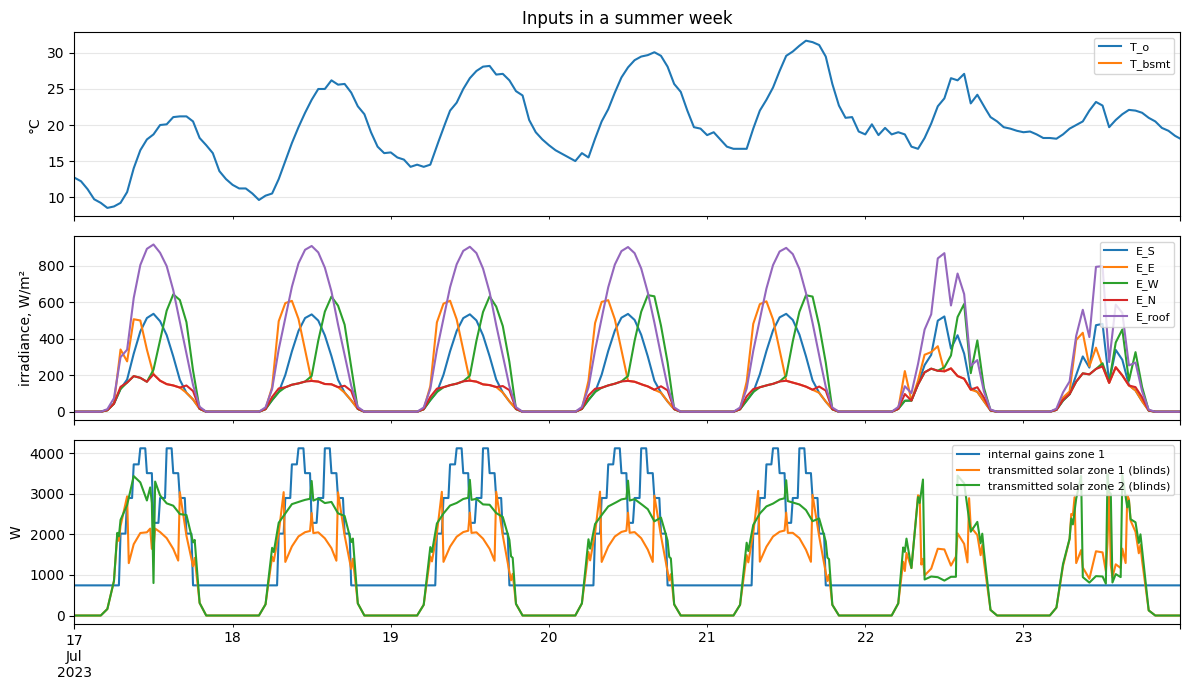

In [7]:
wk = slice(f'{year}-07-17', f'{year}-07-23')                     # a summer week (Monday to Sunday)
fig, axs = plt.subplots(3, 1, figsize=(12, 7), sharex=True)
w.loc[wk, 'T_o'].plot(ax=axs[0], label='T_o')
axs[0].plot(t[(t >= '2023-07-17') & (t < '2023-07-24')], T_bsmt[(t >= '2023-07-17') & (t < '2023-07-24')],
            label='T_bsmt')
w.loc[wk].filter(like='E_').plot(ax=axs[1])
U.loc[wk, f'f: θ{air1} (Q̇occ + Q̇equip + Q̇light)'].plot(ax=axs[2], label='internal gains zone 1')
pd.Series(Q_sol[1], t).loc[wk].plot(ax=axs[2], label='transmitted solar zone 1 (blinds)')
pd.Series(Q_sol[2], t).loc[wk].plot(ax=axs[2], label='transmitted solar zone 2 (blinds)')
axs[0].set(ylabel='°C', title='Inputs in a summer week')
axs[1].set(ylabel='irradiance, W/m²')
axs[2].set(ylabel='W')
for ax in axs:
    ax.legend(fontsize=8, loc='upper right')
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 3 Initial conditions

All states start at 20 °C at the beginning of the warm-up (as in 03CubicBuilding). The largest time constant is
7.9 d with controller and 17.6 d without (Assignment 3), and 20 °C is close to the concrete temperature in
December, so after 30 days the initial value hardly matters.

In [8]:
x0 = np.full(len(states), 20.0)

## 4 Integration in time

$K_p$ of each zone is $10^5$ W/K (on) or 0 (off), which gives four models, each discretised once with implicit
Euler:

$$\theta_{C,k+1} = \Phi\,\theta_{C,k} + \Gamma u_k, \qquad \Phi = (I - \Delta t A_s)^{-1}, \quad
\Gamma = \Phi\,\Delta t B_s$$

$q_{HVAC} = K_p (T_{sp} - \theta_{air})$ is evaluated with the air temperature at the end of the step; the
controller decides on the measured air temperature at the start of the step.

The ventilation of Assignment 1 runs day and night with heat recovery. Two summer measures are added
(assumptions), decided for the whole building from the mean air temperature $\bar\theta$ of both zones at the
start of the step, only when $T_{o,24h}$ > 12 °C (as for the blinds) and $\bar\theta$ > 22 °C:

| Mode | When | $G_v$ per zone |
|---|---|---|
| normal | otherwise | $\rho c\,[(1-\eta)\dot V_{mech} + \dot V_{inf}]$ |
| heat-recovery bypass | $T_o < \bar\theta$ | $\rho c\,(\dot V_{mech} + \dot V_{inf})$, $\eta = 0$ |
| night ventilation | as bypass, not occupied and $T_o < \bar\theta - 2$ K; once on, it runs down to $\bar\theta$ = 21 °C, then the windows stay shut until morning | bypass + motorised windows, 2 air changes per hour |

The ventilation only changes $G$: 3 ventilation modes × 4 controller states = 12 models.

`simulate` has two controllers (MPC in section 6). The P-controller of Assignments 1–3 is always on with the
heating set-point, so it also cools whenever the air is above it. The dead-band controller (as in tutorial
05SwitchModels) switches a zone on with $T_{sp} = T_h$ below $T_h$, with $T_{sp} = T_c$ above $T_c$, and off in
between.

In [9]:
K_on = 1e5                                                       # W/K, gain of the P-controller when on


k_vent = [k for k in bT if src[k] == 'T_o' and branches[k][1] in (air1, air2)]   # ventilation branches
n_night = 2.0                                                    # 1/h, night ventilation by windows (assumption)
V_vent = {'normal': V_mech + V_inf, 'bypass': V_mech + V_inf,
          'night': V_mech + V_inf + n_night * V_air}             # m³/h per zone
G_vent = {'normal': G_v, 'bypass': rho_c_air / 3600 * (V_mech + V_inf),
          'night': rho_c_air / 3600 * V_vent['night']}           # W/K per zone


def discrete(on1, on2, vent='normal', dt_=dt):
    """Implicit Euler model with the controller of zone 1 / zone 2 on (1) or off (0) and a ventilation mode."""
    G_K = G.copy()
    G_K[k_ctrl[0], k_ctrl[0]] = K_on * on1
    G_K[k_ctrl[1], k_ctrl[1]] = K_on * on2
    for k in k_vent:
        G_K[k, k] = G_vent[vent]
    As, Bs, Cs, Ds = dm4bem.tc2ss(A, G_K, C, b_ptr, f_ptr, y_ptr)
    Phi = np.linalg.inv(np.eye(len(As)) - dt_ * As)
    return {'Phi': Phi, 'Gam': Phi @ (dt_ * Bs), 'Cs': Cs}


models = {(i, j): discrete(i, j) for i in (0, 1) for j in (0, 1)}
models_v = {(i, j, v): discrete(i, j, v) for i in (0, 1) for j in (0, 1) for v in G_vent}
Cs = models[(0, 0)]['Cs']                                        # same in all models: the air nodes are states
print(', '.join(f'{v}: G_v = {G_vent[v]:.0f} W/K' for v in G_vent))


def simulate(control, U, x0, k_start=0, k_end=None, mods=models, sched=None, vent=False):
    """Simulation from step k_start to k_end. Returns y (air °C), q_HVAC (W) per zone and the states.

    sched = (T_h, T_c, occupied) on the time axis of U; default: the 15-min schedules.
    vent = True: bypass and night ventilation (15-min time axis only)."""
    T_h, T_c, occupied = sched or (globals()['T_h'], globals()['T_c'], globals()['occupied'])
    Ua = U.to_numpy()
    k_end = k_end or len(Ua)
    m_ = k_end - k_start
    y, q, X = np.zeros((m_, 2)), np.zeros((m_, 2)), np.zeros((m_, len(x0)))
    modes = np.full(m_, 'normal', dtype=object)
    T_o = Ua[:, jb[k_vent[0]]]
    done = False
    x = x0.copy()
    for i, k in enumerate(range(k_start, k_end)):
        X[i] = x
        θ_k = Cs @ x                                             # air at the start of the step (measurement)
        if control == 'P':
            on, sp = (1, 1), np.array([T_h[k], T_h[k]])
        else:                                                    # dead-band
            on, sp = [0, 0], np.array([T_h[k], T_h[k]])
            for j in range(2):
                if θ_k[j] < T_h[k]:
                    on[j], sp[j] = 1, T_h[k]
                elif θ_k[j] > T_c[k]:
                    on[j], sp[j] = 1, T_c[k]
            on = tuple(on)
        m = mods[on]
        if vent:
            θm = θ_k.mean()
            if occupied[k]:
                done = False                                     # night ventilation allowed again next night
            if T_o24[k] > 12 and θm > 22 and T_o[k] < θm:
                modes[i] = 'bypass'
            if T_o24[k] > 12 and not occupied[k] and not done and T_o[k] < θm - 2:
                if i > 0 and modes[i - 1] == 'night' and θm < 21:
                    done = True                                  # stopped at 21 °C: windows stay shut this night
                elif θm > 22 or (i > 0 and modes[i - 1] == 'night'):
                    modes[i] = 'night'
            m = models_v[on + (modes[i],)]
        u = Ua[k].copy()
        u[j_sp] = sp
        x = m['Phi'] @ x + m['Gam'] @ u
        y[i] = Cs @ x                                            # air at the end of the step
        q[i] = K_on * np.array(on) * (sp - y[i])
    return pd.DataFrame({'θ1': y[:, 0], 'θ2': y[:, 1], 'q1': q[:, 0], 'q2': q[:, 1],
                         'T_h': T_h[k_start:k_end], 'T_c': T_c[k_start:k_end],
                         'occupied': occupied[k_start:k_end], 'vent': modes}, index=U.index[k_start:k_end]), X


res, X = {}, {}
for c, control, vent in (('P', 'P', False), ('dead-band', 'dead-band', False),
                         ('dead-band + ventilation', 'dead-band', True)):
    r, X[c] = simulate(control, U, x0, vent=vent)
    res[c] = r.iloc[k0:]                                          # without the warm-up
    X[c] = X[c][k0:]
print('simulated: ' + ', '.join(res))
v = res['dead-band + ventilation']['vent']
print('ventilation modes (h/a): ' + ', '.join(f'{m} {(v == m).sum() * dt / 3600:.0f}' for m in G_vent))

normal: G_v = 50 W/K, bypass: G_v = 167 W/K, night: G_v = 617 W/K


simulated: P, dead-band, dead-band + ventilation
ventilation modes (h/a): normal 5135, bypass 2434, night 1190


## 5 Results

In [10]:
S_tot = 2 * S_plan                                               # m², floor area of both zones


def key_figures(r):
    """Annual energy, peak loads and comfort of a simulation result."""
    q = r[['q1', 'q2']].to_numpy()
    θ = r[['θ1', 'θ2']].to_numpy()
    occ = r['occupied'].to_numpy()[:, None]
    under = np.clip(r[['T_h']].to_numpy() - 0.5 - θ, 0, None) * occ   # K below T_h - 0.5 K during occupancy
    over = np.clip(θ - r[['T_c']].to_numpy() - 0.5, 0, None) * occ     # K above T_c + 0.5 K
    hours = len(r) * dt / 3600
    return pd.Series({
        'heating, kWh': np.clip(q, 0, None).sum() * dt / 3.6e6,
        'cooling, kWh': -np.clip(q, None, 0).sum() * dt / 3.6e6,
        'heating, kWh/m²': np.clip(q, 0, None).sum() * dt / 3.6e6 / S_tot * 8760 / hours,
        'cooling, kWh/m²': -np.clip(q, None, 0).sum() * dt / 3.6e6 / S_tot * 8760 / hours,
        'peak heating (sum of zones), W/m²': q.max(axis=0).sum() / S_tot,
        'peak cooling (sum of zones), W/m²': -q.min(axis=0).sum() / S_tot,
        'under-heating, Kh': under.sum() * dt / 3600,
        'over-heating, Kh': over.sum() * dt / 3600})


fig_tab = pd.DataFrame({c: key_figures(r) for c, r in res.items()})
r = res['dead-band']
for j, name in ((1, 'zone 1 (south)'), (2, 'zone 2 (north)')):
    print(f'dead-band, {name}: heating {r[f"q{j}"].clip(lower=0).sum() * dt / 3.6e6 / S_plan:.1f} kWh/m², '
          f'cooling {-r[f"q{j}"].clip(upper=0).sum() * dt / 3.6e6 / S_plan:.1f} kWh/m²')
fig_tab.round(1)

dead-band, zone 1 (south): heating 3.9 kWh/m², cooling 25.0 kWh/m²
dead-band, zone 2 (north): heating 9.9 kWh/m², cooling 22.8 kWh/m²


,P,dead-band,dead-band + ventilation
"heating, kWh",5297.9,3103.9,3141.8
"cooling, kWh",29558.9,10736.1,3299.1
"heating, kWh/m²",11.8,6.9,7.0
"cooling, kWh/m²",65.7,23.9,7.3
"peak heating (sum of zones), W/m²",39.1,38.6,38.6
"peak cooling (sum of zones), W/m²",39.4,33.7,26.9
"under-heating, Kh",0.0,0.0,0.0
"over-heating, Kh",0.0,0.2,0.3


### Humid air

The thermal model has sensible heat only. Latent loads come from a moisture balance of the air of each zone
(assumptions): air mass $M = \rho V$, outdoor air $\dot m = \rho \dot V$ of the active ventilation mode (the heat
recovery does not transfer moisture), 60 g/h of vapour per person, no moisture storage in the walls, no
humidification in winter. During occupancy the ventilation unit keeps the humidity ratio at most
$w_{max}$ = 12 g/kg (about 60 % at 26 °C); the removed vapour times $h_{fg}$ = 2450 kJ/kg is the latent cooling.

$$M \frac{dw}{dt} = \dot m\,(w_o - w) + \dot m_{occ} - \dot m_{dehum}$$

solved with implicit Euler on the same time step.

In [11]:
g_pers, w_max, h_fg, rho_air = 60 / 3.6e6, 12e-3, 2450e3, 1.2   # kg/s per person, kg/kg, J/kg, kg/m³
n_pers = np.where(workday, p_persons[t.hour] * f_year, 0) * S_plan / 14   # persons per zone
w_out = w['w_o'].to_numpy()


def humidity(r):
    """Humidity ratio (kg/kg) and latent cooling (W, > 0) of one zone along a result with column 'vent'."""
    k = t.get_indexer(r.index)
    M = rho_air * V_air
    m_a = rho_air / 3600 * r['vent'].map(V_vent).to_numpy()
    w_z, q_l = np.zeros(len(r)), np.zeros(len(r))
    x = w_out[k[0]]
    for i, kk in enumerate(k):
        x = (M * x + dt * (m_a[i] * w_out[kk] + g_pers * n_pers[kk])) / (M + dt * m_a[i])
        if occupied[kk] and x > w_max:
            q_l[i] = (x - w_max) * (M + dt * m_a[i]) / dt * h_fg
            x = w_max
        w_z[i] = x
    return pd.DataFrame({'w': w_z, 'q_lat': q_l}, index=r.index)


hum = {c: humidity(r) for c, r in res.items()}                  # zones identical (same flow and occupancy)
fig_tab.loc['latent cooling, kWh/m²'] = [hum[c]['q_lat'].sum() * dt / 3.6e6 / S_plan for c in fig_tab]
fig_tab.loc['cooling incl. latent, kWh/m²'] = fig_tab.loc['cooling, kWh/m²'] + fig_tab.loc['latent cooling, kWh/m²']
fig_tab.round(1)

,P,dead-band,dead-band + ventilation
"heating, kWh",5297.9,3103.9,3141.8
"cooling, kWh",29558.9,10736.1,3299.1
"heating, kWh/m²",11.8,6.9,7.0
"cooling, kWh/m²",65.7,23.9,7.3
"peak heating (sum of zones), W/m²",39.1,38.6,38.6
"peak cooling (sum of zones), W/m²",39.4,33.7,26.9
"under-heating, Kh",0.0,0.0,0.0
"over-heating, Kh",0.0,0.2,0.3
"latent cooling, kWh/m²",0.4,0.4,0.4
"cooling incl. latent, kWh/m²",66.1,24.3,7.7


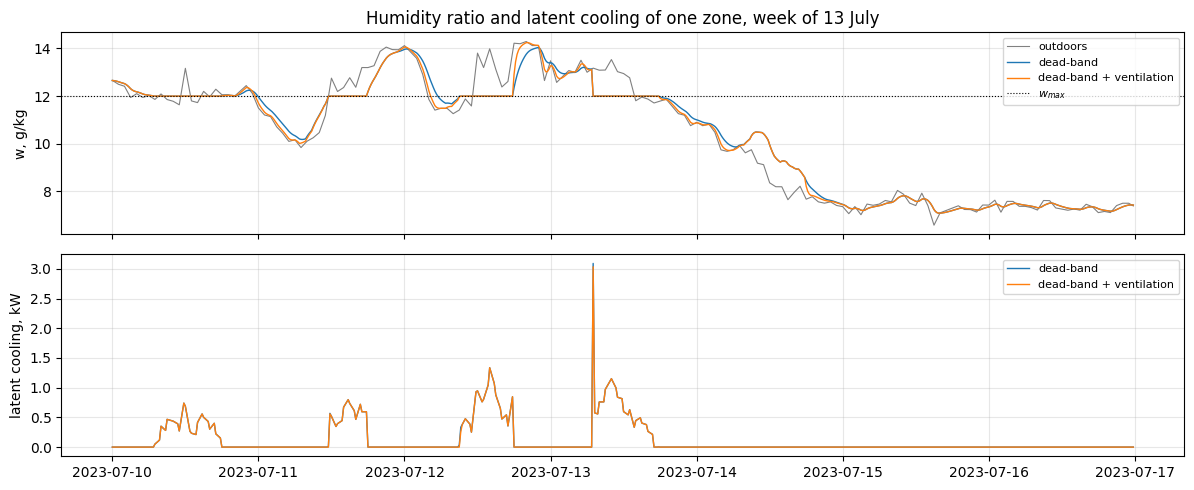

In [12]:
d0 = hum['dead-band + ventilation']['q_lat'].resample('D').sum().idxmax()   # day with the largest latent load
a, b = d0 - pd.Timedelta(days=d0.dayofweek), d0 + pd.Timedelta(days=6 - d0.dayofweek, hours=23.75)
fig, axs = plt.subplots(2, 1, figsize=(12, 5), sharex=True)
axs[0].plot(w.loc[a:b, 'w_o'] * 1e3, color='grey', lw=0.8, label='outdoors')
for c in ('dead-band', 'dead-band + ventilation'):
    axs[0].plot(hum[c].loc[a:b, 'w'] * 1e3, lw=1, label=c)
    axs[1].plot(hum[c].loc[a:b, 'q_lat'] / 1000, lw=1, label=c)
axs[0].axhline(w_max * 1e3, color='k', ls=':', lw=0.8, label='$w_{max}$')
axs[0].set(ylabel='w, g/kg', title=f'Humidity ratio and latent cooling of one zone, week of {d0:%d %B}')
axs[1].set(ylabel='latent cooling, kW')
for ax in axs:
    ax.legend(fontsize=8, loc='upper right')
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

A winter and a summer week (Monday to Sunday), P-controller and dead-band. Grey band: between heating and
cooling set-point.

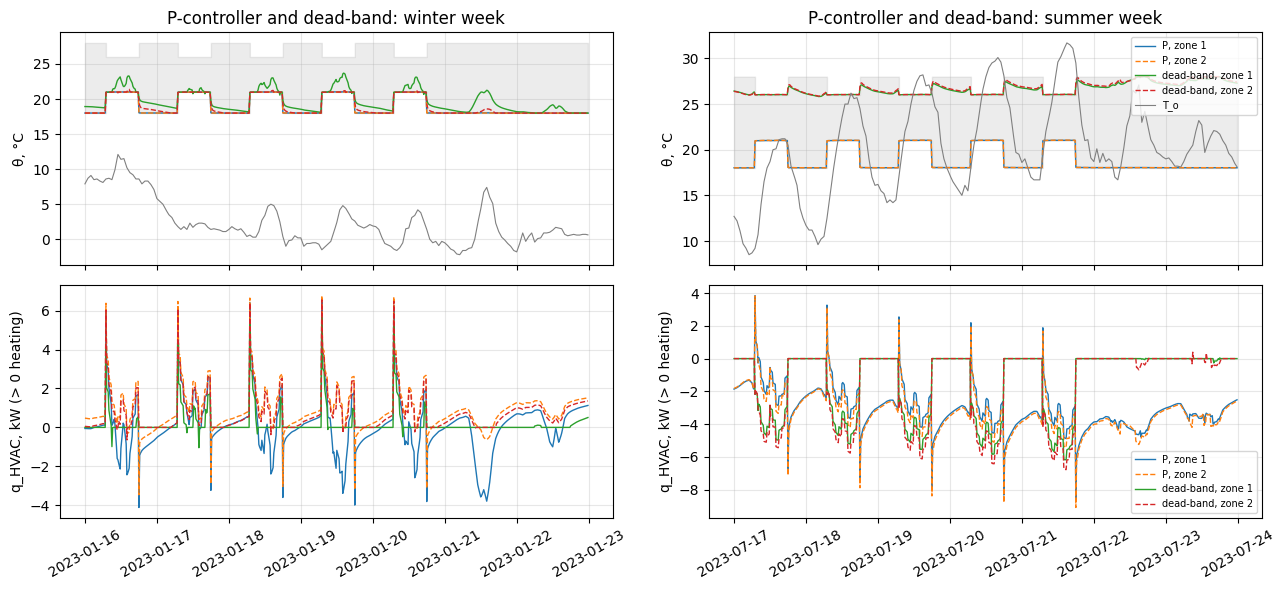

In [13]:
weeks = {'winter week': (f'{year}-01-16', f'{year}-01-22 23:45'),
         'summer week': (f'{year}-07-17', f'{year}-07-23 23:45')}


def plot_week(rs, title):
    """Air temperatures and q_HVAC of several results in one week."""
    fig, axs = plt.subplots(2, 2, figsize=(13, 6), sharex='col')
    for col, (wname, (a, b)) in enumerate(weeks.items()):
        for name, r in rs.items():
            r = r.loc[a:b]
            for j, ls in ((1, '-'), (2, '--')):
                axs[0, col].plot(r.index, r[f'θ{j}'], ls, lw=1, label=f'{name}, zone {j}')
                axs[1, col].plot(r.index, r[f'q{j}'] / 1000, ls, lw=1, label=f'{name}, zone {j}')
        r = next(iter(rs.values())).loc[a:b]
        axs[0, col].fill_between(r.index, r['T_h'], r['T_c'], color='grey', alpha=0.15, step='post')
        axs[0, col].plot(w.loc[a:b, 'T_o'], color='grey', lw=0.8, label='T_o')
        axs[0, col].set(title=f'{title}: {wname}', ylabel='θ, °C')
        axs[1, col].set(ylabel='q_HVAC, kW (> 0 heating)')
        axs[1, col].tick_params(axis='x', rotation=30)
    for ax in axs.flat:
        ax.grid(alpha=0.3)
    axs[0, 1].legend(fontsize=7, loc='upper right')
    axs[1, 1].legend(fontsize=7, loc='lower right')
    plt.tight_layout()
    plt.show()


plot_week({c: res[c] for c in ('P', 'dead-band')}, 'P-controller and dead-band')

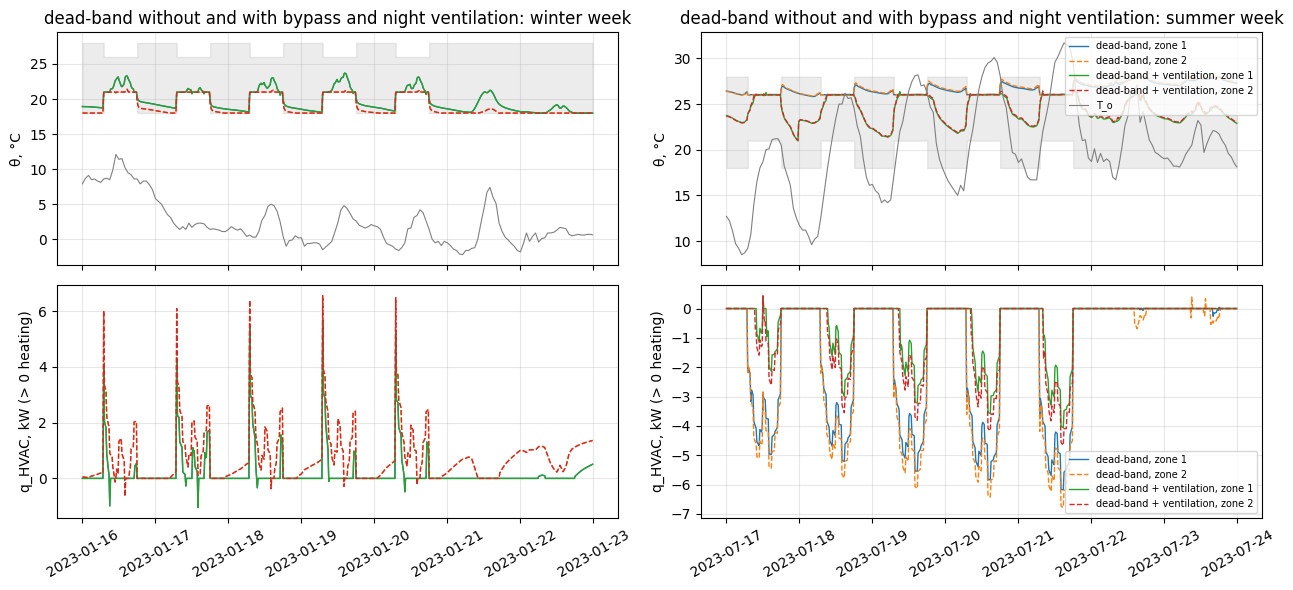

In [14]:
plot_week({c: res[c] for c in ('dead-band', 'dead-band + ventilation')}, 'dead-band without and with bypass and night ventilation')

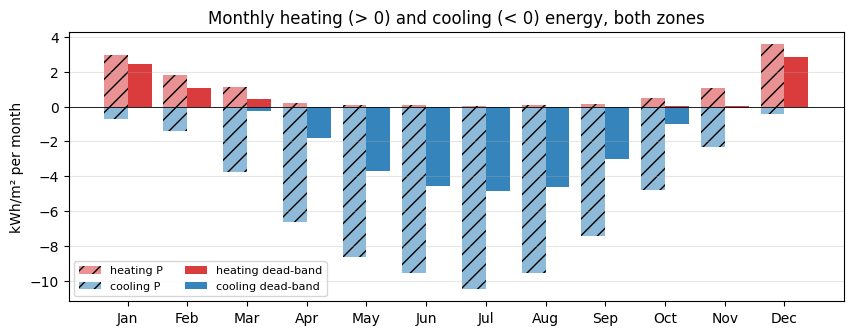

In [15]:
mon = pd.DataFrame({
    'heating P': res['P'][['q1', 'q2']].clip(lower=0).sum(axis=1),
    'cooling P': res['P'][['q1', 'q2']].clip(upper=0).sum(axis=1),
    'heating dead-band': res['dead-band'][['q1', 'q2']].clip(lower=0).sum(axis=1),
    'cooling dead-band': res['dead-band'][['q1', 'q2']].clip(upper=0).sum(axis=1),
}).resample('MS').sum() * dt / 3.6e6 / S_tot
fig, ax = plt.subplots(figsize=(10, 3.5))
x_m = np.arange(12)
for i, (col, color, hatch) in enumerate([('heating P', 'tab:red', '//'), ('cooling P', 'tab:blue', '//'),
                                         ('heating dead-band', 'tab:red', ''), ('cooling dead-band', 'tab:blue', '')]):
    ax.bar(x_m + (i // 2 - 0.5) * 0.4, mon[col], 0.4, color=color, alpha=0.5 if hatch else 0.9, hatch=hatch,
           label=col)
ax.set(xticks=x_m, xticklabels=mon.index.strftime('%b'), ylabel='kWh/m² per month',
       title='Monthly heating (> 0) and cooling (< 0) energy, both zones')
ax.axhline(0, color='k', lw=0.6)
ax.legend(fontsize=8, ncol=2)
ax.grid(axis='y', alpha=0.3)
plt.show()

Time step check: both weeks again with the dead-band controller at 5 min, starting from the states of the
annual simulation.

In [16]:
dt_f = 300
models_f = {key: discrete(*key, dt_=dt_f) for key in models}
U_f = U.resample(f'{dt_f}s').ffill()                              # inputs constant within 15 min
t_f = U_f.index
sched_f = tuple(pd.Series(v, t).reindex(t_f, method='ffill').to_numpy() for v in (T_h, T_c, occupied))
for wname, (a, b) in weeks.items():
    r15 = res['dead-band'].loc[a:b]
    ka, kb = t_f.get_loc(pd.Timestamp(a)), t_f.get_loc(pd.Timestamp(b)) + 1
    xa = X['dead-band'][res['dead-band'].index.get_loc(pd.Timestamp(a))]
    r5, _ = simulate('dead-band', U_f, xa, ka, kb, models_f, sched_f)
    e15 = r15[['q1', 'q2']].abs().sum().sum() * dt / 3.6e6
    e5 = r5[['q1', 'q2']].abs().sum().sum() * dt_f / 3.6e6
    print(f'{wname}: heating + cooling {e15:.1f} kWh (Δt = 15 min), {e5:.1f} kWh (Δt = 5 min), '
          f'difference {(e15 - e5) / e5:+.1%}; max |Δθ_air| = '
          f'{np.abs(r15["θ1"].values - r5["θ1"].resample(f"{dt}s").last().values[:len(r15)]).max():.2f} K')

winter week: heating + cooling 154.3 kWh (Δt = 15 min), 153.2 kWh (Δt = 5 min), difference +0.7%; max |Δθ_air| = 0.43 K


summer week: heating + cooling 493.3 kWh (Δt = 15 min), 493.1 kWh (Δt = 5 min), difference +0.0%; max |Δθ_air| = 0.19 K


## 6 Model predictive control (MPC)

The MPC uses the model with $K_p = 0$ and adds $q_{HVAC}$ of each zone to the air node. Every hour it solves a
linear program over 24 h with a perfect forecast of all inputs; $q_{HVAC}$ is decided per 15 min for the first 4 h
and hourly after that, the air temperature is checked every step:

$$\min \; \sum_h \left(q_{h} + q_{c}\right) \cdot 1\,\text{h} \; + \; \lambda \left(\hat q_h + \hat q_c\right)
\; + \; \rho \sum s$$

$$T_h - s \le \theta_{air} \le T_c + s, \qquad 0 \le q_h \le \hat q_h, \quad 0 \le q_c \le \hat q_c,
\quad q_h, q_c \le P_{max}, \qquad s \ge 0$$

with $q_{HVAC} = q_h - q_c$ and $\hat q_h$, $\hat q_c$ the peak powers per zone in the horizon. The air
temperature is $\theta_{air} = \theta_{free} + H q$, with $\theta_{free}$ the prediction for $q = 0$ and $H$ from
$C_s \Phi^m \Gamma_q$. The slack $s$ (penalty $\rho$ = 1000 kWh/K) keeps the problem feasible;
$P_{max}$ = 30 kW per zone (assumption, about 5 times the design heating load). The first hour is applied, then
the plan is recalculated (receding horizon).

"MPC, energy" uses $\lambda = 0$; "MPC, energy + peak" uses $\lambda$ = 4 kWh per kW (assumption, e.g. a demand
charge). Both run for the winter and summer week from the dead-band states, with the normal ventilation
(the bypass and night ventilation would make the model time-varying).

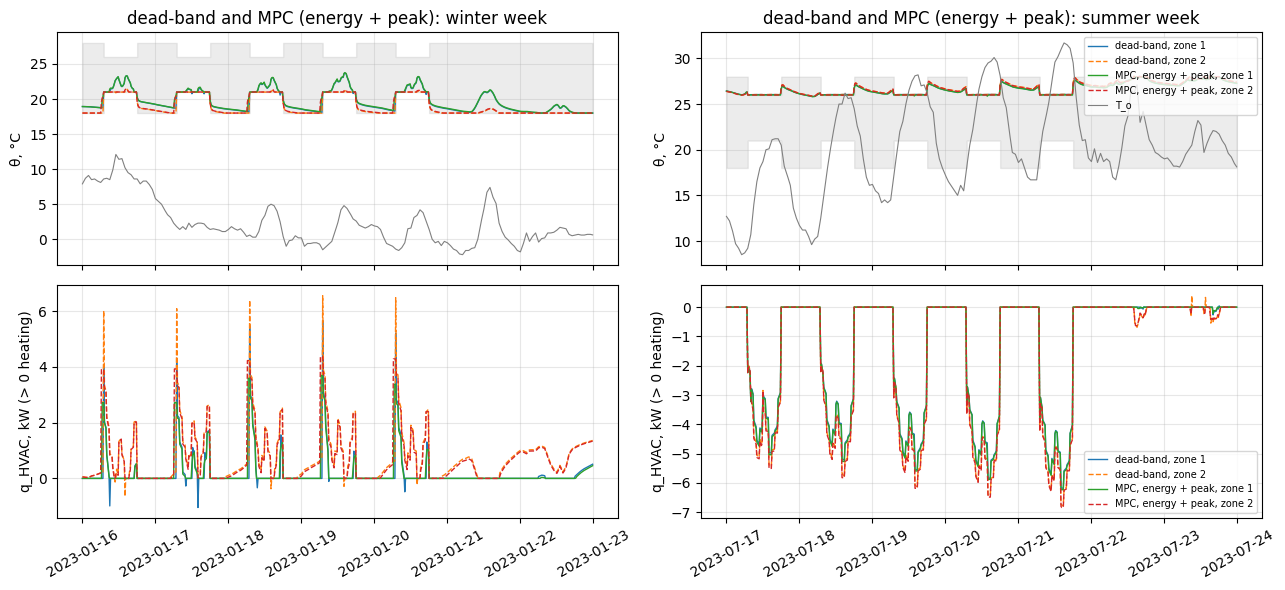

In [17]:
m0 = models[(0, 0)]
Phi0, Gam0 = m0['Phi'], m0['Gam']
j_q = [jf[air1], jf[air2]]                                       # inputs of the air nodes: q_HVAC is added here
N, P_max, rho = 96, 30e3, 1000.0                                 # horizon: 96 steps of 15 min = 24 h
block = np.r_[np.arange(16), 16 + (np.arange(16, N) - 16) // 4]  # decision of each step: 15 min for 4 h, then hourly
n_h = block.max() + 1                                            # number of decisions per zone
hours = np.bincount(block) * dt / 3600                           # h, duration of each decision

Hm, Pm = [], np.eye(len(states))                                 # Hm[m] = Cs Φ^m Γ_q (2 × 2)
for m in range(N):
    Hm.append(Cs @ Pm @ Gam0[:, j_q])
    Pm = Phi0 @ Pm
H = np.zeros((2 * N, 2 * N))                                     # air at the end of steps k … k+N-1 <- q
for r_ in range(N):
    for c_ in range(r_ + 1):
        H[2 * r_:2 * r_ + 2, 2 * c_:2 * c_ + 2] = Hm[r_ - c_]
E_h = np.zeros((2 * N, 2 * n_h))                                 # q of the time steps <- q of the decisions
for i in range(N):
    E_h[2 * i:2 * i + 2, 2 * block[i]:2 * block[i] + 2] = np.eye(2)
H_h = H @ E_h
n_v = 6 * n_h + 4                                                # variables: q_h, q_c, s (per decision, zone), peaks
Z = np.zeros((2 * N, 4))
A_comfort = np.block([[-H_h, H_h, -E_h, Z], [H_h, -H_h, -E_h, Z]])
A_peak = np.zeros((4 * n_h, n_v))                                # q_h - peak_h ≤ 0, q_c - peak_c ≤ 0
for i in range(2 * n_h):
    A_peak[i, i], A_peak[i, 6 * n_h + i % 2] = 1, -1
    A_peak[2 * n_h + i, 2 * n_h + i], A_peak[2 * n_h + i, 6 * n_h + 2 + i % 2] = 1, -1
A_ub = np.vstack([A_comfort, A_peak])
bounds = [(0, P_max)] * (4 * n_h) + [(0, None)] * (2 * n_h + 4)


def mpc(U, x0, k_start, k_end, lam):
    """MPC from step k_start to k_end with peak weight lam (kWh per kW). Returns the same table as simulate."""
    e = np.repeat(hours, 2) * 1e-3                               # kWh per W of each decision
    c_lp = np.r_[e, e, np.full(2 * n_h, rho), np.full(4, lam * 1e-3)]
    Ua = U.to_numpy()
    y, q = np.zeros((k_end - k_start, 2)), np.zeros((k_end - k_start, 2))
    x = x0.copy()
    for i0 in range(0, k_end - k_start, 4):
        k = k_start + i0
        xf, y_free = x.copy(), np.zeros(2 * N)                   # free prediction (q = 0)
        for m in range(N):
            xf = Phi0 @ xf + Gam0 @ Ua[min(k + m, len(Ua) - 1)]
            y_free[2 * m:2 * m + 2] = Cs @ xf
        kk = np.minimum(np.arange(k, k + N), len(Ua) - 1)        # set-points of the steps k … k+N-1
        lo, hi = np.repeat(T_h[kk], 2), np.repeat(T_c[kk], 2)
        sol = linprog(c_lp, A_ub=A_ub, b_ub=np.r_[y_free - lo, hi - y_free, np.zeros(4 * n_h)],
                      bounds=bounds, method='highs')
        plan = (sol.x[:2 * n_h] - sol.x[2 * n_h:4 * n_h]).reshape(n_h, 2)
        for m in range(min(4, k_end - k)):                        # apply the first hour of the plan
            u = Ua[k + m].copy()
            u[j_q] += plan[m]
            x = Phi0 @ x + Gam0 @ u
            y[i0 + m], q[i0 + m] = Cs @ x, plan[m]               # air at the end of the step, q during the step
    sl = slice(k_start, k_end)
    return pd.DataFrame({'θ1': y[:, 0], 'θ2': y[:, 1], 'q1': q[:, 0], 'q2': q[:, 1], 'T_h': T_h[sl], 'T_c': T_c[sl],
                         'occupied': occupied[sl]}, index=U.index[sl])


res_w = {'dead-band': [], 'MPC, energy': [], 'MPC, energy + peak': []}
for wname, (a, b) in weeks.items():
    ka, kb = t.get_loc(pd.Timestamp(a)), t.get_loc(pd.Timestamp(b)) + 1
    xa = X['dead-band'][res['dead-band'].index.get_loc(pd.Timestamp(a))]
    res_w['dead-band'].append(res['dead-band'].loc[a:b])
    res_w['MPC, energy'].append(mpc(U, xa, ka, kb, lam=0))
    res_w['MPC, energy + peak'].append(mpc(U, xa, ka, kb, lam=4))
res_w = {c: pd.concat(v) for c, v in res_w.items()}
plot_week({c: res_w[c] for c in ('dead-band', 'MPC, energy + peak')}, 'dead-band and MPC (energy + peak)')

In [18]:
tab_w = {}
for wname, (a, b) in weeks.items():
    for c, r in res_w.items():
        kf = key_figures(r.loc[a:b])
        tab_w[(wname, c)] = kf[['heating, kWh', 'cooling, kWh', 'peak heating (sum of zones), W/m²', 'peak cooling (sum of zones), W/m²',
                                'under-heating, Kh', 'over-heating, Kh']]
pd.DataFrame(tab_w).round(1)

winter week                                 \
                                    dead-band MPC, energy MPC, energy + peak   
heating, kWh                            153.1       154.1              162.2   
cooling, kWh                              1.2        -0.0               -0.0   
peak heating (sum of zones), W/m²        27.1        27.7               17.9   
peak cooling (sum of zones), W/m²         3.7        -0.0               -0.0   
under-heating, Kh                         0.0         0.0                0.0   
over-heating, Kh                          0.0         0.0                0.0   

                                  summer week                                 
                                    dead-band MPC, energy MPC, energy + peak  
heating, kWh                              0.2         0.0                0.0  
cooling, kWh                            493.1       497.5              497.7  
peak heating (sum of zones), W/m²         1.0         0.0                0.0  
peak cooling (sum of zones), W/m²        28.8        29.1               29.0  
under-heating, Kh                         0.0         0.0                0.0  
over-heating, Kh                          0.0         0.0                0.0

## 7 Discussion

Inputs: 1138 kWh/(m²·a) south, 732 east, 829 west, 468 north, 1449 roof (the time correction mostly moves
radiation between east and west); internal gains 58.7 kWh/(m²·a).

P-controller: one set-point for heating and cooling, so it cools to 21 °C by day and 18 °C at night in summer and
cools the sunlit south zone in winter. 11.8 kWh/(m²·a) heating and 65.7 kWh/(m²·a) cooling: fine for steady state
and step response, not for a year.

Dead-band: 6.9 kWh/(m²·a) heating, 23.9 kWh/(m²·a) cooling (south 3.9 / 25.0, north 9.9 / 22.8), against 8.1 and
12.4 kWh/(m²·a) from SIA 2024 (room type 3.01, Chur). Cooling is about double: the heat recovery also runs in
summer and the building stays at 26–27 °C at night although it is often 10–20 °C outside; blinds only above
200 W/m², so the north windows (60 % of the façade) are hardly shaded. The peak heating load of
38.6 W/m² exceeds the design load of 24.6 W/m² (Assignment 2) since the set-point jumps from 18 to 21 °C at 07:00
and the unlimited controller re-heats in about one step. In winter the south zone floats up to about 24 °C while
the north zone is heated, partly via the interior wall; in summer the unshaded north zone needs more cooling. The
symmetric P-controller of the active mode also gives 19 kWh cooling and 10 kWh heating per year in the wrong mode.

Bypass and night ventilation: cooling drops from 23.9 to 7.3 kWh/(m²·a) and the peak from 33.7 to 26.9 W/m²;
heating stays at 7.0 kWh/(m²·a), since both only run when $T_{o,24h}$ > 12 °C. The bypass runs 2434 h and the
night ventilation 1190 h per year. Night air cools the concrete, which then takes up heat during the day. With
it the model is below the SIA 2024 value; the windows are assumed to open whenever needed (no rain, wind or
security limits) and fan energy is not counted.

Humid air: the latent cooling is only 0.4 kWh/(m²·a), the same with and without night ventilation (dehumidified
only during occupancy). The outdoor air in Chur is above 12 g/kg for 348 h a year (on 40 days), and only the
excess during occupancy is removed. With latent load the cooling is 7.7 kWh/(m²·a).

Time step: 5 min instead of 15 min changes the energy by less than 1 % and the air temperature by at most 0.4 K.

MPC: with energy only it matches the dead-band controller within 1 %, as both heat as late as possible. With the
peak in the cost (4 kWh per kW) it pre-heats into the thermal mass and cuts the winter-week peak by 34 %
(27.1 to 17.9 W/m²) for about 6 % more heating energy. The peak term only covers the 24 h horizon; a monthly
demand charge would need the peak already reached as a constraint. The summer peak stays, because pre-cooling the
concrete costs more than it saves; night ventilation does this for free (above).

Limits: ideal controllers (dead-band without power limit, MPC with 30 kW and perfect forecast), latent load from a
simple moisture balance, MPC without bypass and night ventilation, convective gains, one typical year (weather about half an hour early, as values sit
at the start of their hour and are interpolated), hypotheses of Assignment 1 (e.g. star network for long-wave
radiation, constant coefficients).